# Supervisor e Hierarquias

Um **supervisor** é um agente que recebe o pedido, decide a cada passo qual especialista trabalha e usa o resultado para escolher o passo seguinte. Esse **controle centralizado** produz uma **delegação dinâmica**, enquanto em um workflow fixo a ordem dos passos está no código. Equipes de agentes constroem aqui uma To-Do List e um agregador de notícias em Streamlit, com um supervisor e depois com uma **hierarquia**.

In [1]:
# No Google Colab, descomente e rode uma vez.

# !pip install -q langchain langchain-openai langgraph streamlit

# import os
# from google.colab import userdata

# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")

In [2]:
import json
import re
import shutil
import subprocess
import sys
import tempfile
from collections import Counter
from pathlib import Path
from typing import Literal
from urllib.parse import urlencode
from urllib.request import urlopen

from IPython.display import Image
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from langchain.tools import tool
from langgraph.graph import START, END, MessagesState, StateGraph
from langgraph.types import Command
from pydantic import BaseModel

In [3]:
model = init_chat_model(
    "openai:gpt-5.4-mini",
    reasoning_effort="low",
    use_responses_api=True,
    output_version="v0",
    timeout=120,
)

supervisor_model = init_chat_model(
    "openai:gpt-5.4-mini",
    reasoning_effort="low",
    use_responses_api=True,
    output_version="v0",
    timeout=120,
    model_kwargs={"parallel_tool_calls": False},
)

In [4]:
def user_message(text):
    """Monta a entrada do agente com uma mensagem do usuário."""
    return {"messages": [{"role": "user", "content": text}]}

Os agentes escrevem arquivos de verdade em uma pasta de trabalho, com as ferramentas abaixo, que usam só o nome do arquivo para não sair da pasta. As aplicações geradas abrem com `streamlit run` dentro dessa pasta, em um terminal.

In [5]:
WORKDIR = Path("workspace")
WORKDIR.mkdir(exist_ok=True)


@tool
def write_file(path: str, content: str) -> str:
    """Escreve um arquivo na pasta de trabalho, substituindo o conteúdo anterior."""
    (WORKDIR / Path(path).name).write_text(content)
    return f"{path} salvo com {len(content.splitlines())} linhas."


@tool
def read_file(path: str) -> str:
    """Lê um arquivo da pasta de trabalho."""
    file = WORKDIR / Path(path).name
    return file.read_text() if file.is_file() else f"{path} não existe."

## Supervisor

No LangGraph, o supervisor é um nó que lê a conversa e devolve um `Command(goto=...)` com o próximo nó, e cada especialista é um nó que volta ao supervisor. Todos leem o mesmo histórico, e a resposta de cada especialista entra nele como uma mensagem com o nome dele. A equipe tem um desenvolvedor backend, que escreve a lógica em Python, e um desenvolvedor frontend, que escreve a interface em Streamlit.

In [ ]:
BACKEND_PROMPT = """# Papel
Você é um desenvolvedor backend Python.

# Regras
Escreva só a lógica, em funções Python, e salve os arquivos com write_file.
Nunca escreva arquivos de interface, mesmo que o pedido cite um: a interface fica com o frontend.
Para alterar um arquivo existente, leia-o antes com read_file.
Responda em até cinco linhas com os arquivos salvos, a assinatura de cada função pública e as chaves dos dicionários que ela devolve."""

In [ ]:
FRONTEND_PROMPT = """# Papel
Você é um desenvolvedor frontend que escreve interfaces em Streamlit.

# Regras
A interface chama as funções do backend e não reimplementa a lógica. Use st.rerun, e não st.experimental_rerun.
Salve os arquivos com write_file. Para alterar um arquivo existente, leia-o antes com read_file.
Responda em até três linhas com os arquivos salvos e o que mudou neles."""

In [ ]:
backend_agent = create_agent(model, tools=[write_file, read_file], system_prompt=BACKEND_PROMPT)
frontend_agent = create_agent(model, tools=[write_file, read_file], system_prompt=FRONTEND_PROMPT)

In [7]:
class Route(BaseModel):
    next: Literal["backend", "frontend", "FINISH"]


SUPERVISOR_PROMPT = """# Papel
Você coordena uma equipe de desenvolvimento e não escreve código.

# Equipe
- backend escreve a lógica em Python;
- frontend escreve a interface em Streamlit, que usa as funções do backend.

# Regras
Leia a conversa e escolha quem trabalha a seguir.
Responda FINISH assim que as mensagens da equipe atenderem o pedido do usuário."""

In [8]:
def supervisor_node(state: MessagesState) -> Command[Literal["backend", "frontend", "__end__"]]:
    """Escolhe o próximo membro da equipe ou encerra."""
    messages = [{"role": "system", "content": SUPERVISOR_PROMPT}] + state["messages"]
    route = model.with_structured_output(Route).invoke(messages)
    print("supervisor:", route.next)
    if route.next == "FINISH":
        return Command(goto=END)
    return Command(goto=route.next)

In [9]:
def backend_node(state: MessagesState) -> Command[Literal["supervisor"]]:
    """Roda o backend sobre a conversa e devolve a resposta ao supervisor."""
    result = backend_agent.invoke(state)
    message = HumanMessage(content=result["messages"][-1].text, name="backend")
    return Command(goto="supervisor", update={"messages": [message]})


def frontend_node(state: MessagesState) -> Command[Literal["supervisor"]]:
    """Roda o frontend sobre a conversa e devolve a resposta ao supervisor."""
    result = frontend_agent.invoke(state)
    message = HumanMessage(content=result["messages"][-1].text, name="frontend")
    return Command(goto="supervisor", update={"messages": [message]})

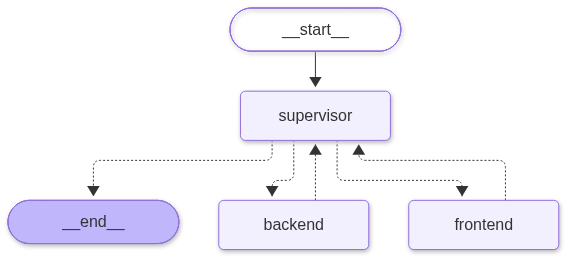

In [11]:
builder = StateGraph(MessagesState)
builder.add_node("supervisor", supervisor_node)
builder.add_node("backend", backend_node)
builder.add_node("frontend", frontend_node)
builder.add_edge(START, "supervisor")

graph = builder.compile()
Image(graph.get_graph().draw_mermaid_png())

In [12]:
%%time
graph_result = graph.invoke(user_message(
    "Crie uma To-Do List em Streamlit, com cadastro, listagem, conclusão e remoção de tarefas, guardadas em tasks.json. A lógica fica em todo.py e a interface em todo_app.py."
))

supervisor: backend


supervisor: frontend


supervisor: FINISH
CPU times: user 487 ms, sys: 27.9 ms, total: 515 ms
Wall time: 23.4 s


In [13]:
for message in graph_result["messages"]:
    print(f"{message.name or 'usuário'}: {message.content}\n")

usuário: Crie uma To-Do List em Streamlit, com cadastro, listagem, conclusão e remoção de tarefas, guardadas em tasks.json. A lógica fica em todo.py e a interface em todo_app.py.

backend: Salvei `todo.py` com a lógica de persistência em `tasks.json`.  
Funções públicas: `load_tasks(file_path='tasks.json') -> list[dict]` (chaves: `id, title, done, created_at, completed_at`), `save_tasks(tasks, file_path='tasks.json') -> None`.  
Funções públicas: `add_task(title, file_path='tasks.json') -> dict` (chaves: `task, tasks`), `list_tasks(file_path='tasks.json') -> dict` (chaves: `tasks, total, done_count, pending_count`).  
Funções públicas: `complete_task(task_id, file_path='tasks.json') -> dict` (chaves: `updated, tasks`), `remove_task(task_id, file_path='tasks.json') -> dict` (chaves: `removed, tasks`).  
Não escrevi `todo_app.py` porque a interface deve ficar com o frontend.

frontend: Arquivo salvo: `todo_app.py`.  
Criei a interface em Streamlit com cadastro, listagem, conclusão e remo

In [14]:
%%time
title_result = graph.invoke(user_message(
    "Na interface da To-Do List, em todo_app.py, troque o título da página para Minhas Tarefas."
))

supervisor: frontend


supervisor: FINISH
CPU times: user 119 ms, sys: 5.16 ms, total: 124 ms
Wall time: 9.48 s


O supervisor chamou o backend, depois o frontend, e encerrou com FINISH. O backend viu no histórico compartilhado o pedido da interface e deixou `todo_app.py` para o frontend, por causa da regra do prompt, e o frontend usou as funções que o backend listou na resposta. No pedido do título, o supervisor chamou só o frontend.

### Exercício 1

Acrescente ao grafo um nó documentador, que escreve um README.md com o que a aplicação faz e como executá-la. Atualize `Route`, o prompt do supervisor e o grafo, e peça a documentação da To-Do List. Por quais nós o pedido passou?

In [ ]:
# Seu código aqui

## Subagentes como ferramentas

A mesma equipe pode ser montada com `create_agent`: cada especialista vira um **subagente**, chamado como ferramenta pelo supervisor. O subagente roda em uma conversa nova e vê só a tarefa que o supervisor escreveu, então o frontend só conhece as funções do backend se a tarefa disser quais são. O `supervisor_model` desliga as chamadas paralelas, para que o supervisor delegue uma tarefa de cada vez.

In [16]:
@tool
def backend(task: str) -> str:
    """Entrega ao desenvolvedor backend uma tarefa sobre a lógica em Python."""
    result = backend_agent.invoke(user_message(task))
    return result["messages"][-1].text


@tool
def frontend(task: str) -> str:
    """Entrega ao desenvolvedor frontend uma tarefa sobre a interface em Streamlit."""
    result = frontend_agent.invoke(user_message(task))
    return result["messages"][-1].text

In [17]:
DEV_PROMPT = """# Papel
Você supervisiona uma equipe de desenvolvimento e não escreve código.

# Regras
Cada tarefa traz tudo de que o membro precisa, porque ele não vê esta conversa:
os nomes dos arquivos, as chaves dos arquivos de dados que o pedido citar e, para o frontend, o arquivo,
as funções e as chaves dos dados que o backend entregou.
Responda em até cinco linhas com os arquivos entregues."""

dev_agent = create_agent(
    supervisor_model,
    tools=[backend, frontend],
    system_prompt=DEV_PROMPT,
)

In [17]:
%%time
dev_result = dev_agent.invoke(user_message(
    "Crie uma To-Do List em Streamlit, com cadastro, listagem, conclusão e remoção de tarefas, guardadas em tasks.json. A lógica fica em todo.py e a interface em todo_app.py."
))

CPU times: user 170 ms, sys: 6.35 ms, total: 176 ms
Wall time: 21.5 s


In [ ]:
def delegations(result, size=300):
    """Mostra cada ferramenta que o supervisor chamou, com o começo da tarefa e da resposta."""
    answers = {m.tool_call_id: m.text for m in result["messages"] if m.type == "tool"}
    for message in result["messages"]:
        for call in getattr(message, "tool_calls", []):
            task = " ".join(map(str, call["args"].values()))
            print(f"{call['name']}\n  tarefa: {task[:size]}\n  resposta: {answers[call['id']][:size]}\n")

In [19]:
delegations(dev_result)

backend
  tarefa: Implemente a lógica da To-Do List no arquivo todo.py usando tasks.json como persistência. Crie funções para: carregar tarefas, salvar tarefas, cadastrar nova tarefa, listar tarefas, marcar tarefa como concluída e remover tarefa. Estruture cada tarefa com ao menos id, titulo, concluida e criada_em; m
  resposta: Arquivo salvo: `todo.py`.
Funções públicas: `carregar_tarefas(arquivo='tasks.json') -> list[dict]`, `salvar_tarefas(tarefas, arquivo='tasks.json') -> None`, `cadastrar_nova_tarefa(titulo, arquivo='tasks.json') -> dict`, `listar_tarefas(arquivo='tasks.json') -> list[dict]`, `marcar_tarefa_concluida(t

frontend
  tarefa: Crie a interface Streamlit da To-Do List no arquivo todo_app.py consumindo o backend de todo.py. Use as funções carregadas: carregar_tarefas, salvar_tarefas, cadastrar_nova_tarefa, listar_tarefas, marcar_tarefa_concluida e remover_tarefa. Na tela, exiba um formulário para cadastrar tarefa com campo 
  resposta: Arquivo salvo: `todo_app.py`  
Crie

O supervisor escreveu cada tarefa por conta própria. Na do backend, ele sugeriu nomes de funções em português, que o backend adotou; na do frontend, copiou as funções que o backend devolveu, porque o frontend só vê essa tarefa. No grafo, todos os nós leem o mesmo histórico, e com ferramentas cada subagente recebe só a tarefa que o supervisor escreveu.

### Exercício 2

Transforme o documentador do Exercício 1 em uma ferramenta e monte um supervisor com `DEV_PROMPT` e as ferramentas `backend`, `frontend` e a nova. Peça a ele a documentação da To-Do List. Quais ferramentas o supervisor chamou, e o que a tarefa do documentador dizia sobre os arquivos?

In [ ]:
# Seu código aqui

## Delegação iterativa

Um testador escreve testes e os roda com `run_tests`, em uma cópia da pasta de trabalho que protege os dados. Quando um teste falha, o supervisor decide quem corrige e pede o teste de novo, até aprovar. Esse ciclo sai do prompt do supervisor, e não de um laço no código, e o `recursion_limit` limita os passos do grafo do agente se o teste nunca aprovar.

In [21]:
@tool
def run_tests(code: str) -> str:
    """Executa um programa Python em uma cópia da pasta de trabalho e devolve o que ele imprimiu e os erros."""
    with tempfile.TemporaryDirectory() as folder:
        shutil.copytree(WORKDIR, folder, dirs_exist_ok=True)
        process = subprocess.run([sys.executable, "-c", code], cwd=folder, capture_output=True, text=True, timeout=60)
    return process.stdout[-3000:] + process.stderr[-3000:]

In [ ]:
TESTER_PROMPT = """# Papel
Você é um testador.

# Regras
Leia o código com read_file e escreva os testes como um programa Python simples, sem pytest,
que importa os arquivos e imprime o resultado de cada teste. Rode-o com run_tests.
Teste uma interface Streamlit com AppTest.from_file(arquivo).run(), de streamlit.testing.v1: ela falha se app.exception não estiver vazio.
Teste o código como está, sem corrigi-lo.
Responda APROVADO se todos os testes passaram, ou REPROVADO com cada falha, em até dez linhas."""

In [ ]:
tester_agent = create_agent(model, tools=[read_file, run_tests], system_prompt=TESTER_PROMPT)

In [ ]:
@tool
def test(task: str) -> str:
    """Entrega ao testador o código a testar, com os nomes dos arquivos e o que o código deve fazer."""
    result = tester_agent.invoke(user_message(task))
    return result["messages"][-1].text

In [ ]:
DEV_LEAD_PROMPT = DEV_PROMPT + """
Com o código pronto, envie os arquivos ao test, com o que o pedido exige deles.
Se o teste reprovar, envie cada falha a quem escreveu o arquivo e teste de novo. Responda só quando o teste aprovar."""

In [ ]:
dev_lead_agent = create_agent(
    supervisor_model,
    tools=[backend, frontend, test],
    system_prompt=DEV_LEAD_PROMPT,
).with_config(recursion_limit=60)

In [26]:
%%time
lead_result = dev_lead_agent.invoke(user_message(
    "Teste a To-Do List, com a lógica em todo.py e a interface em todo_app.py, e corrija o que falhar. Concluir ou remover uma tarefa que não existe deve levantar KeyError."
))

CPU times: user 685 ms, sys: 53.7 ms, total: 739 ms
Wall time: 1min 23s


In [27]:
delegations(lead_result)

backend
  tarefa: Arquivo: todo.py. Ajuste a lógica da To-Do List para que concluir() e remover() lancem KeyError quando a tarefa não existir. Garanta que as operações de adicionar, listar, concluir e remover continuem funcionando corretamente com essa regra.
  resposta: Arquivo salvo: `todo.py`.
Funções públicas: `carregar_tarefas(arquivo: str = TASKS_FILE) -> List[Dict[str, Any]]`, `salvar_tarefas(tarefas: List[Dict[str, Any]], arquivo: str = TASKS_FILE) -> None`, `cadastrar_nova_tarefa(titulo: str, arquivo: str = TASKS_FILE) -> Dict[str, Any]`, `listar_tarefas(ar

frontend
  tarefa: Arquivo: todo_app.py. Use as funções de todo.py: cadastrar_nova_tarefa, listar_tarefas, marcar_tarefa_concluida e remover_tarefa. A interface em Streamlit deve exibir a lista, permitir cadastrar, concluir e remover tarefas. Quando marcar como concluída ou remover uma tarefa inexistente, deixe o KeyE
  resposta: Salvei `todo_app.py` com uma interface Streamlit que usa apenas `cadastrar_nova_tarefa`, `list

O supervisor mandou o backend levantar `KeyError` em `todo.py` e o frontend acompanhar a mudança, e só então pediu o teste. A primeira rodada reprovou: a interface chamava a função de cadastro com os argumentos invertidos. O supervisor repassou a falha ao frontend, e a rodada seguinte aprovou. O `DEV_LEAD_PROMPT` só acrescenta ao `DEV_PROMPT` a regra do teste, e o número de rodadas saiu dos resultados dos testes.

### Exercício 3

Crie um subagente revisor, que lê o código e aponta só os erros que o fariam falhar, e um supervisor com as ferramentas de `dev_lead_agent` e o revisor, cujo prompt acrescenta ao `DEV_LEAD_PROMPT` uma revisão antes de cada teste. Peça a mesma tarefa da To-Do List. Em que ordem as ferramentas foram chamadas?

In [ ]:
# Seu código aqui

## Hierarquias

Em uma **hierarquia**, um subagente é ele próprio um supervisor com subagentes. Um supervisor geral vai coordenar a equipe de desenvolvimento, que é o `dev_lead_agent`, e uma equipe de dados, com um buscador e um analista de notícias. A busca usa a API pública do Hacker News e guarda as notícias em `news_raw.json`, devolvendo ao modelo só os títulos. A ferramenta `data_team` recebe só um tema.

In [ ]:
@tool
def search_news(query: str) -> str:
    """Busca as notícias mais recentes no Hacker News e acrescenta as cinco primeiras a news_raw.json."""
    url = "https://hn.algolia.com/api/v1/search_by_date?" + urlencode({"query": query, "tags": "story", "hitsPerPage": 5})
    hits = json.loads(urlopen(url, timeout=30).read())["hits"]
    file = WORKDIR / "news_raw.json"
    news = json.loads(file.read_text()) if file.exists() else []
    news += [{"title": hit["title"], "date": hit["created_at"], "points": hit["points"], "link": hit.get("url") or f"https://news.ycombinator.com/item?id={hit['objectID']}"} for hit in hits]
    file.write_text(json.dumps(news, ensure_ascii=False, indent=2))
    return "\n".join(hit["title"] for hit in hits) or "Nenhuma notícia encontrada com esses termos."

In [ ]:
NEWS_FORMAT = ("news é a lista de notícias, cada uma com title, date, points (votos no Hacker News), link e topic, sem resumo. "
               "topics é a lista de assuntos, cada um com topic, count e summary, que é o resumo do assunto.")


@tool
def save_analysis(path: str, topics: list[str], summaries: dict[str, str]) -> str:
    """Salva em path as notícias de news_raw.json. Em topics vai o assunto de cada notícia,
    na ordem do arquivo, e em summaries o resumo de cada assunto."""
    news = json.loads((WORKDIR / "news_raw.json").read_text())
    if not news:
        return "news_raw.json está vazio: não há notícias para salvar."
    if len(topics) != len(news):
        return f"São {len(news)} notícias e {len(topics)} assuntos. Envie um assunto por notícia."
    for item, topic in zip(news, topics):
        item["topic"] = topic
    counts = Counter(topics)
    data = {"news": news, "topics": [{"topic": t, "count": counts[t], "summary": summaries.get(t, "")} for t in counts]}
    (WORKDIR / Path(path).name).write_text(json.dumps(data, ensure_ascii=False, indent=2))
    return f"{path} salvo com duas chaves. {NEWS_FORMAT}"

O formato do arquivo de análise fica no código, em `NEWS_FORMAT`, e não nos prompts. `save_analysis` e `data_team` o devolvem na resposta, para que ele chegue inteiro às outras equipes.

In [ ]:
SEARCHER_PROMPT = """# Papel
Você busca notícias.

# Regras
Faça duas buscas para cada tema pedido. Cada busca tem uma ou duas palavras-chave em inglês, como AI ou solar power,
sem palavras como news ou recent, porque a busca exige todas as palavras no título.
Responda em até três linhas com quantas notícias encontrou."""

In [ ]:
ANALYST_PROMPT = """# Papel
Você analisa notícias.

# Regras
Leia news_raw.json com read_file e escolha você, lendo os títulos, um assunto específico para cada notícia,
como regulação ou chips. Use de três a cinco assuntos, nenhum com mais da metade das notícias.
Salve com save_analysis no arquivo indicado na tarefa, com um resumo em português do que as notícias de cada assunto dizem.
Responda com o arquivo e as chaves que save_analysis informou."""

In [ ]:
searcher_agent = create_agent(model, tools=[search_news], system_prompt=SEARCHER_PROMPT)
analyst_agent = create_agent(model, tools=[read_file, save_analysis], system_prompt=ANALYST_PROMPT)

In [ ]:
@tool
def searcher(task: str) -> str:
    """Entrega ao buscador os temas das notícias que ele deve buscar."""
    return searcher_agent.invoke(user_message(task))["messages"][-1].text


@tool
def analyst(task: str) -> str:
    """Entrega ao analista as notícias encontradas para classificar e resumir por assunto."""
    return analyst_agent.invoke(user_message(task))["messages"][-1].text

In [ ]:
DATA_PROMPT = """# Papel
Você supervisiona uma equipe de dados e não executa tarefas.

# Regras
1. Peça ao searcher as notícias do tema.
2. Peça ao analyst que classifique as notícias e salve a análise no arquivo do pedido.
3. Responda com o arquivo e as chaves que o analista informou."""

data_lead_agent = create_agent(supervisor_model, tools=[searcher, analyst], system_prompt=DATA_PROMPT).with_config(recursion_limit=60)

In [ ]:
team_results = {"data_team": [], "dev_team": []}


@tool
def data_team(theme: str) -> str:
    """Entrega à equipe de dados um tema curto, como energia solar. Ela busca e analisa as notícias e devolve o arquivo gerado e suas chaves."""
    (WORKDIR / "news_raw.json").unlink(missing_ok=True)
    file = "news_" + "_".join(re.findall(r"\w+", theme.lower())) + ".json"
    result = data_lead_agent.invoke(user_message(f"Busque e analise notícias sobre {theme}. Salve a análise em {file}."))
    team_results["data_team"].append(result)
    return f"{result['messages'][-1].text}\n\nFormato de {file}: {NEWS_FORMAT}"

In [ ]:
@tool
def dev_team(task: str) -> str:
    """Entrega à equipe de desenvolvimento uma aplicação para construir e testar."""
    team_results["dev_team"].append(dev_lead_agent.invoke(user_message(task)))
    return team_results["dev_team"][-1]["messages"][-1].text

In [ ]:
GENERAL_PROMPT = """# Papel
Você é o supervisor geral e coordena duas equipes, sem executar tarefas.

# Equipes
- data_team recebe um tema, busca notícias reais e devolve um arquivo JSON com a análise;
- dev_team constrói aplicações em Python e Streamlit, com testes, e não tem acesso à internet.

# Regras
Quando a aplicação precisa de dados, a data_team trabalha antes da dev_team.
A dev_team não vê esta conversa nem o trabalho da data_team: copie literalmente
na tarefa dela os arquivos e as chaves do JSON que a data_team devolveu.
Responda em até cinco linhas com os arquivos entregues."""

In [ ]:
general_agent = create_agent(
    supervisor_model,
    tools=[data_team, dev_team],
    system_prompt=GENERAL_PROMPT,
).with_config(recursion_limit=60)

In [28]:
%%time
general_result = general_agent.invoke(user_message(
    "Crie em Streamlit um agregador de notícias sobre inteligência artificial. As notícias são o destaque da página, cada uma em um bloco com o título grande, o assunto e o link da fonte. Ao lado delas fica um gráfico com o número de notícias por assunto. A interface fica em news_app.py."
))

CPU times: user 840 ms, sys: 58.6 ms, total: 898 ms
Wall time: 1min 2s


In [29]:
delegations(general_result)

data_team
  tarefa: inteligência artificial
  resposta: Arquivo salvo: `news_inteligência_artificial.json`

Chaves informadas pelo analista:
- `news`: lista de notícias, cada item com `title`, `date`, `points`, `link` e `topic`
- `topics`: lista de assuntos, cada item com `topic`, `count` e `summary`

Formato de news_inteligência_artificial.json: news é 

dev_team
  tarefa: Criar uma aplicação em Streamlit no arquivo `news_app.py` usando os dados do arquivo `news_inteligência_artificial.json`.

Requisitos da interface:
- As notícias são o destaque da página.
- Cada notícia deve aparecer em um bloco/card com:
  - título grande
  - assunto
  - link da fonte
- Ao lado dos
  resposta: Arquivos entregues: `news_app.py`  
Testes entregues: validação de carregamento local, chaves `news`/`topics`, agrupamento por assunto e execução sem internet.  
Status: aprovado.



In [30]:
delegations(team_results["data_team"][-1])

searcher
  tarefa: Busque notícias recentes sobre inteligência artificial, abrangendo avanços tecnológicos, lançamentos de produtos, regulação, impactos econômicos e casos de uso relevantes.
  resposta: Fiz 2 buscas sobre IA e encontrei 10 notícias no total.  
Cobri avanços tecnológicos, lançamentos, regulação, impactos econômicos e casos de uso.  
Se quiser, posso agora resumir as manchetes mais relevantes.

analyst
  tarefa: Classifique e resuma as notícias encontradas sobre inteligência artificial em temas principais. Salve a análise no arquivo news_inteligência_artificial.json. Informe também as chaves/estruturas usadas no arquivo final.
  resposta: Arquivo salvo: `news_inteligência_artificial.json`

Chaves/estruturas no arquivo final:
- `news`: lista de notícias, cada item com `title`, `date`, `points`, `link` e `topic`
- `topics`: lista de assuntos, cada item com `topic`, `count` e `summary`



In [31]:
delegations(team_results["dev_team"][-1])

frontend
  tarefa: Criar a interface principal em `news_app.py` usando `news_inteligência_artificial.json`. A página deve destacar as notícias em cards/blocos com título grande, assunto (`topic`) e link da fonte (`link`). Ao lado da lista de notícias, exibir um gráfico com o número de notícias por assunto, usando os d
  resposta: Salvo: `news_app.py` — criei a interface principal em Streamlit, lendo o JSON local e exibindo as notícias em cards com título, `topic` e link.  
Também adicionei funções puras reutilizáveis (`carregar_json`, `agrupar_por_assunto`, `preparar_dados_do_grafico`, `renderizar_cards`) e um gráfico latera

test
  tarefa: Testar o arquivo `news_app.py` com foco em: (1) carregamento local do `news_inteligência_artificial.json` sem acesso à internet; (2) leitura correta das chaves `news` e `topics`; (3) agrupamento/contagem por assunto consistente com os dados; (4) presença das funções puras esperadas para facilitar te
  resposta: APROVADO

Testes automatizados executa

O supervisor geral chamou a `data_team` com o tema e, com o arquivo e as chaves que ela devolveu, escreveu a tarefa da `dev_team`. Cada equipe repetiu dentro dela o padrão do supervisor: a de dados chamou o searcher e o analyst, e a de desenvolvimento chamou o frontend e o test, sem o backend, porque a aplicação só lê o arquivo pronto. O supervisor geral recebeu só as respostas finais das equipes.

### Exercício 4

Peça ao `general_agent` um agregador que compare as notícias sobre inteligência artificial com as notícias sobre energia solar. Em que ordem o supervisor geral chamou as equipes, e o que ele repassou de uma equipe para a outra?

In [ ]:
# Seu código aqui